# **From Bounding Boxes to Oriented Bounding Boxes for Satellite/Drone Image Analytics**


## Author: Dr. Sujoy Kumar Biswas, Ph.D. (EE/CS), M.Tech. (CS)
##         Head, Research & Innovation
##         IDEAS - Technology Innovation Hub
##         Indian Statistical Institute (ISI), Kolkata

## Secondary Affiliation: Founder, AIMP LABS (www.aimplabs.org)

## Target Audience  : IDEAS-TIH Research & Engineering Interns (Autumn 2026)

## Mini-workshop: From Bounding Boxes to Oriented Bounding Boxes

**Learning objectives**

By the end, you should understand:

1. Why an axis-aligned bounding box can be a poor representation.
2. What an oriented bounding box (OBB) is.
3. How OBB annotations are represented.
4. How YOLO OBB differs from standard YOLO detection.
5. How to visualize OBB annotations.
6. How to use a pretrained YOLO26-OBB model for inference.
7. How YOLO internally represents an OBB as (x, y, w, h, rotation).
8. That OBB models can also be trained with YOLO—but we will not train or validate anything in this exercise.
Ultralytics' current OBB models use the -obb suffix, and the official YOLO26 OBB models are pretrained on DOTA-v1

In [ ]:
!pip -q install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 4.0 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = "cuda:0"
else:
    print("WARNING: Running on CPU")
    device = "cpu"

print("Using device:", device)

CUDA available: True
GPU: Tesla T4
Using device: cuda:0


In [ ]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/dota128.zip
!unzip -q dota128.zip -d /content/

In [ ]:
DATASET_DIR = Path("/content/dota128")

IMAGE_DIR = DATASET_DIR / "images" / "train"
LABEL_DIR = DATASET_DIR / "labels" / "train"

images = sorted(IMAGE_DIR.glob("*"))

print("Number of images:", len(images))
print("Image directory:", IMAGE_DIR)
print("Label directory:", LABEL_DIR)

Number of images: 128
Image directory: /content/dota128/images/train
Label directory: /content/dota128/labels/train


In [ ]:
CLASS_NAMES = {
    0: "plane",
    1: "ship",
    2: "storage tank",
    3: "baseball diamond",
    4: "tennis court",
    5: "basketball court",
    6: "ground track field",
    7: "harbor",
    8: "bridge",
    9: "large vehicle",
    10: "small vehicle",
    11: "helicopter",
    12: "roundabout",
    13: "soccer ball field",
    14: "swimming pool"
}

for k, v in CLASS_NAMES.items():
    print(f"{k:2d} : {v}")

 0 : plane
 1 : ship
 2 : storage tank
 3 : baseball diamond
 4 : tennis court
 5 : basketball court
 6 : ground track field
 7 : harbor
 8 : bridge
 9 : large vehicle
10 : small vehicle
11 : helicopter
12 : roundabout
13 : soccer ball field
14 : swimming pool


In [ ]:
image_path = random.choice(images)

label_path = LABEL_DIR / f"{image_path.stem}.txt"

print("Image:", image_path.name)
print("Label:", label_path.name)

print("\nRAW LABEL FILE\n")
print(label_path.read_text())

Image: P0270__1024__0___203.jpg
Label: P0270__1024__0___203.txt

RAW LABEL FILE

10 0.770507 0.0546876 0.750977 0.0527344 0.75293 0.010742 0.770507 0.0117186
9 0.660156 0.378907 0.649413 0.393555 0.575195 0.360352 0.582031 0.344727
9 0.632813 0.670898 0.625976 0.690429 0.544922 0.661132 0.551757 0.641601
9 0.633789 0.611329 0.621093 0.63086 0.548828 0.595703 0.55664 0.578125
9 0.630859 0.637696 0.618164 0.655273 0.543945 0.625977 0.553711 0.604493
9 0.645508 0.503906 0.635742 0.523438 0.55664 0.492187 0.566406 0.473633
9 0.642578 0.452148 0.62793 0.471679 0.555665 0.435546 0.565429 0.416015
9 0.640625 0.425781 0.630859 0.444336 0.555665 0.407226 0.564454 0.391602
9 0.651367 0.402343 0.640625 0.421874 0.565429 0.38379 0.575195 0.367188
9 0.790039 0.142579 0.777344 0.123047 0.842774 0.083008 0.855469 0.100586
10 0.720703 0.0439453 0.702148 0.0439453 0.704102 -2.08616e-07 0.72168 0.000976369
9 0.780273 0.170898 0.770507 0.151368 0.845703 0.115235 0.852539 0.132813
9 0.786133 0.197265 0.77

In [ ]:
import pandas as pd

image_path = random.choice(images)
label_path = LABEL_DIR / f"{image_path.stem}.txt"

print("Image:", image_path.name)
print("Label:", label_path.name)

# YOLO-OBB columns
columns = [
    "class_id",
    "x1", "y1",
    "x2", "y2",
    "x3", "y3",
    "x4", "y4"
]

# Read annotation file
df = pd.read_csv(
    label_path,
    sep=r"\s+",
    header=None,
    names=columns
)

print("\nYOLO-OBB ANNOTATIONS\n")
display(df)

Image: P1357__1024__0___524.jpg
Label: P1357__1024__0___524.txt

YOLO-OBB ANNOTATIONS



,class_id,x1,y1,x2,y2,x3,y3,x4,y4
0,8,0.699219,0.558594,0.710938,0.553711,0.712891,0.557617,0.701172,0.563477
1,8,0.222656,0.186523,0.230469,0.182617,0.236328,0.195312,0.227539,0.199219
2,8,0.380859,0.125000,0.395508,0.119141,0.401367,0.132812,0.386719,0.139648
3,8,0.150391,0.590820,0.156250,0.585938,0.159180,0.589844,0.152344,0.594727
4,8,0.227539,0.728516,0.238281,0.724609,0.242188,0.730469,0.231445,0.734375
5,8,0.785156,0.922852,0.796875,0.916992,0.797852,0.920898,0.787109,0.926758
6,8,0.651367,0.376953,0.667969,0.373047,0.667969,0.377930,0.652344,0.380859
7,8,0.750000,0.318359,0.754883,0.315430,0.759766,0.324219,0.755859,0.326172
8,8,0.531250,0.068359,0.551758,0.061523,0.555664,0.071289,0.536133,0.079102
9,8,0.164062,0.201172,0.177734,0.196289,0.184570,0.213867,0.171875,0.218750


In [ ]:
columns = [
    "class_id",
    "x1", "y1",
    "x2", "y2",
    "x3", "y3",
    "x4", "y4"
]

df = pd.read_csv(
    label_path,
    sep=r"\s+",
    header=None,
    names=columns
)

df.insert(
    1,
    "class_name",
    df["class_id"].map(CLASS_NAMES)
)

display(df)

,class_id,class_name,x1,y1,x2,y2,x3,y3,x4,y4
0,8,bridge,0.699219,0.558594,0.710938,0.553711,0.712891,0.557617,0.701172,0.563477
1,8,bridge,0.222656,0.186523,0.230469,0.182617,0.236328,0.195312,0.227539,0.199219
2,8,bridge,0.380859,0.125000,0.395508,0.119141,0.401367,0.132812,0.386719,0.139648
3,8,bridge,0.150391,0.590820,0.156250,0.585938,0.159180,0.589844,0.152344,0.594727
4,8,bridge,0.227539,0.728516,0.238281,0.724609,0.242188,0.730469,0.231445,0.734375
5,8,bridge,0.785156,0.922852,0.796875,0.916992,0.797852,0.920898,0.787109,0.926758
6,8,bridge,0.651367,0.376953,0.667969,0.373047,0.667969,0.377930,0.652344,0.380859
7,8,bridge,0.750000,0.318359,0.754883,0.315430,0.759766,0.324219,0.755859,0.326172
8,8,bridge,0.531250,0.068359,0.551758,0.061523,0.555664,0.071289,0.536133,0.079102
9,8,bridge,0.164062,0.201172,0.177734,0.196289,0.184570,0.213867,0.171875,0.218750


In [ ]:
image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

print("Image size:")
print("Width :", width)
print("Height:", height)

Image size:
Width : 1024
Height: 1024


In [ ]:
def read_obb_labels(label_path, image_width, image_height):

    objects = []

    for line in label_path.read_text().strip().splitlines():

        values = line.split()

        class_id = int(values[0])

        coords = np.array(
            list(map(float, values[1:9]))
        ).reshape(4, 2)

        # normalized → pixel coordinates
        coords[:, 0] *= image_width
        coords[:, 1] *= image_height

        objects.append({
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
            "points": coords
        })

    return objects

In [ ]:
gt_objects = read_obb_labels(
    label_path,
    width,
    height
)

print("Objects:", len(gt_objects))

for obj in gt_objects[:5]:
    print(obj)

Objects: 127
{'class_id': 10, 'class_name': 'small vehicle', 'points': array([[        789,          56],
       [        769,          54],
       [        771,          11],
       [        789,          12]])}
{'class_id': 9, 'class_name': 'large vehicle', 'points': array([[        676,         388],
       [        665,         403],
       [        589,         369],
       [        596,         353]])}
{'class_id': 9, 'class_name': 'large vehicle', 'points': array([[        648,         687],
       [        641,         707],
       [        558,         677],
       [        565,         657]])}
{'class_id': 9, 'class_name': 'large vehicle', 'points': array([[        649,         626],
       [        636,         646],
       [        562,         610],
       [        570,         592]])}
{'class_id': 9, 'class_name': 'large vehicle', 'points': array([[        646,         653],
       [        633,         671],
       [        557,         641],
       [        567,        

In [ ]:
def draw_obb_annotations(image, objects):

    output = image.copy()

    for obj in objects:

        points = obj["points"].astype(np.int32)

        cv2.polylines(
            output,
            [points],
            isClosed=True,
            color=(0, 255, 0),
            thickness=2
        )

        x, y = points[0]

        cv2.putText(
            output,
            obj["class_name"],
            (x, max(15, y - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1,
            cv2.LINE_AA
        )

    return output

In [ ]:
def obb_to_aabb(points):

    x_min = points[:, 0].min()
    y_min = points[:, 1].min()

    x_max = points[:, 0].max()
    y_max = points[:, 1].max()

    return [x_min, y_min, x_max, y_max]

In [ ]:
def draw_aabb_vs_obb(image, objects):

    output = image.copy()

    for obj in objects:

        points = obj["points"].astype(np.int32)

        # OBB
        cv2.polylines(
            output,
            [points],
            True,
            (0, 255, 0),
            2
        )

        # AABB
        x1, y1, x2, y2 = map(
            int,
            obb_to_aabb(points)
        )

        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

    return output

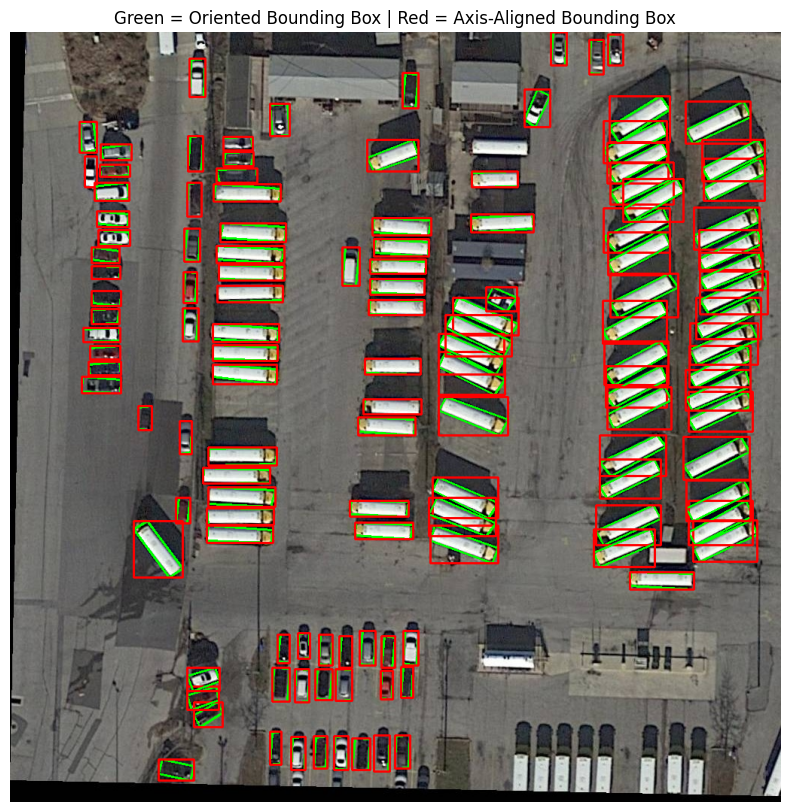

In [ ]:
comparison = draw_aabb_vs_obb(
    image,
    gt_objects
)

plt.figure(figsize=(14, 10))
plt.imshow(comparison)
plt.title(
    "Green = Oriented Bounding Box | Red = Axis-Aligned Bounding Box"
)
plt.axis("off")
plt.show()

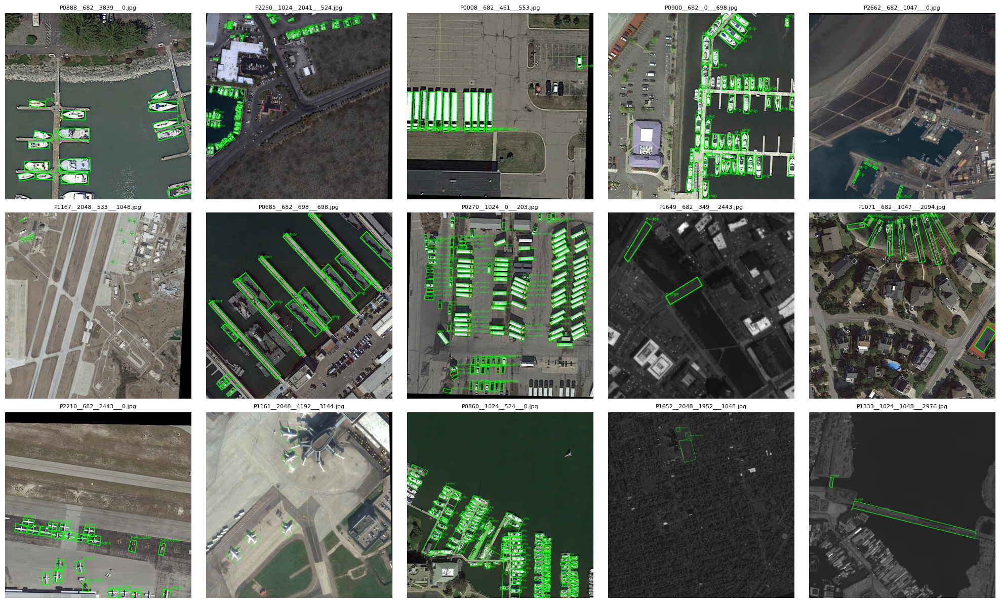

In [ ]:
# Part 10 — Show 15 random images with OBB annotations
sample_images = random.sample(images, 15)

fig, axes = plt.subplots(
    3, 5,
    figsize=(20, 12)
)

for ax, image_path in zip(
    axes.flat,
    sample_images
):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    h, w = image.shape[:2]

    label_path = (
        LABEL_DIR /
        f"{image_path.stem}.txt"
    )

    objects = read_obb_labels(
        label_path,
        w,
        h
    )

    annotated = draw_obb_annotations(
        image,
        objects
    )

    ax.imshow(annotated)
    ax.set_title(
        image_path.name,
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class_counts = {}

for image_path in images:

    label_path = (
        LABEL_DIR /
        f"{image_path.stem}.txt"
    )

    objects = read_obb_labels(
        label_path,
        1,
        1
    )

    for obj in objects:

        name = obj["class_name"]

        class_counts[name] = (
            class_counts.get(name, 0) + 1
        )

class_counts

{'small vehicle': 467,
 'large vehicle': 253,
 'harbor': 117,
 'plane': 199,
 'swimming pool': 1,
 'baseball diamond': 8,
 'storage tank': 213,
 'tennis court': 19,
 'ship': 708,
 'bridge': 46,
 'soccer ball field': 2,
 'ground track field': 8,
 'roundabout': 14,
 'helicopter': 4}

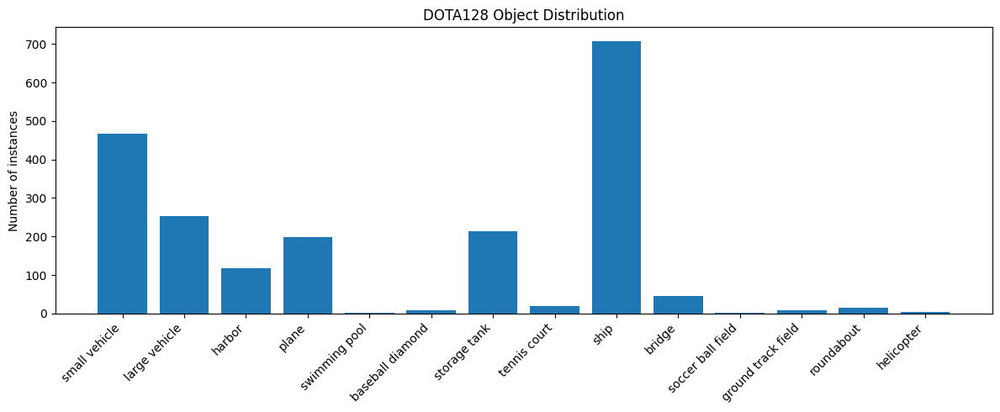

In [ ]:
plt.figure(figsize=(12, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("Number of instances")
plt.title("DOTA128 Object Distribution")

plt.tight_layout()
plt.show()

## Can a refactored YOLO model actually predict these oriented boxes?

Ultralytics provides pretrained YOLO26-OBB models trained on DOTA-v1. The models are named with the -obb suffix, e.g. yolo26n-obb.pt

In [ ]:
obb_model = YOLO("yolo26n-obb.pt")

print("Model loaded.")
print("Device:", device)

Model loaded.
Device: cuda:0


In [ ]:
image_path = random.choice(images)

results = obb_model.predict(
    source=str(image_path),
    imgsz=1024,
    conf=0.25,
    device=device,
    verbose=False
)

result = results[0]

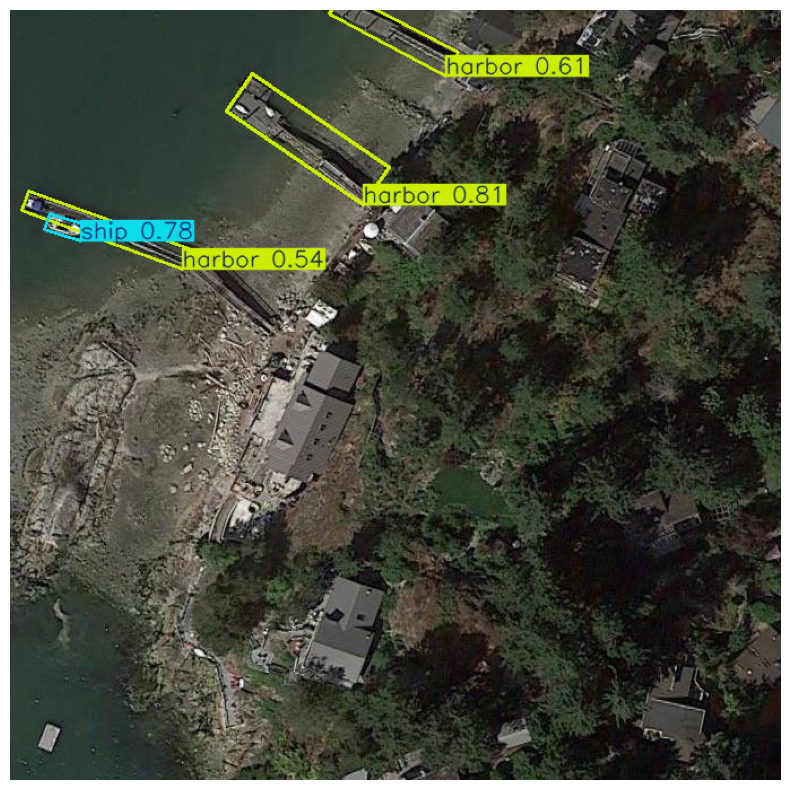

In [ ]:
annotated = result.plot(
    font_size=8,
    line_width=2
)

plt.figure(figsize=(14, 10))

plt.imshow(
    cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.show()

In [ ]:
print("xywhr:")
print(result.obb.xywhr)

print("\nCorner points:")
print(result.obb.xyxyxyxy)

print("\nClasses:")
print(result.obb.cls)

print("\nConfidence:")
print(result.obb.conf)

xywhr:
tensor([[2.6348e+02, 1.1460e+02, 1.4631e+02, 4.0612e+01, 6.0587e-01],
        [4.8643e+01, 1.9282e+02, 3.2860e+01, 1.4405e+01, 3.0824e-01],
        [3.3929e+02, 2.0595e+01, 1.1707e+02, 2.3281e+01, 4.9090e-01],
        [8.4531e+01, 1.9473e+02, 1.5149e+02, 1.8458e+01, 3.4712e-01]], device='cuda:0')

Corner points:
tensor([[[312.0475, 172.9479],
         [335.1749, 139.5650],
         [214.9060,  56.2440],
         [191.7786,  89.6269]],

        [[ 62.1136, 204.6671],
         [ 66.4837, 190.9412],
         [ 35.1727, 180.9723],
         [ 30.8026, 194.6982]],

        [[385.4250,  58.4548],
         [396.4000,  37.9234],
         [293.1568, -17.2650],
         [282.1818,   3.2663]],

        [[152.6194, 229.1757],
         [158.8985, 211.8189],
         [ 16.4427, 160.2834],
         [ 10.1636, 177.6401]]], device='cuda:0')

Classes:
tensor([7., 1., 7., 7.], device='cuda:0')

Confidence:
tensor([0.8149, 0.7751, 0.6066, 0.5354], device='cuda:0')


In [ ]:
obb = result.obb

for i in range(len(obb)):

    cx, cy, w, h, angle = (
        obb.xywhr[i].cpu().numpy()
    )

    cls_id = int(
        obb.cls[i].item()
    )

    confidence = float(
        obb.conf[i].item()
    )

    print(
        f"{i}: "
        f"{result.names[cls_id]} | "
        f"confidence={confidence:.2f} | "
        f"center=({cx:.1f},{cy:.1f}) | "
        f"w={w:.1f} | "
        f"h={h:.1f} | "
        f"angle={angle:.3f} rad"
    )

0: harbor | confidence=0.81 | center=(263.5,114.6) | w=146.3 | h=40.6 | angle=0.606 rad
1: ship | confidence=0.78 | center=(48.6,192.8) | w=32.9 | h=14.4 | angle=0.308 rad
2: harbor | confidence=0.61 | center=(339.3,20.6) | w=117.1 | h=23.3 | angle=0.491 rad
3: harbor | confidence=0.54 | center=(84.5,194.7) | w=151.5 | h=18.5 | angle=0.347 rad


In [ ]:
for i in range(len(obb)):

    angle_rad = float(
        obb.xywhr[i][4].item()
    )

    angle_deg = np.degrees(angle_rad)

    print(
        f"{i}: {angle_deg:.1f}°"
    )

0: 34.7°
1: 17.7°
2: 28.1°
3: 19.9°


In [ ]:
corners = result.obb.xyxyxyxy.cpu().numpy()

print(
    "Shape:",
    corners.shape
)

Shape: (4, 4, 2)


In [ ]:
print(corners[0])

[[     312.05      172.95]
 [     335.17      139.56]
 [     214.91      56.244]
 [     191.78      89.627]]


                 DATASET
                    │
          class + 4 corner points
                    │
                    ▼
             YOLO OBB MODEL
                    │
                    ▼
       class + 4 predicted corners
                    │
                    ▼
              visualization

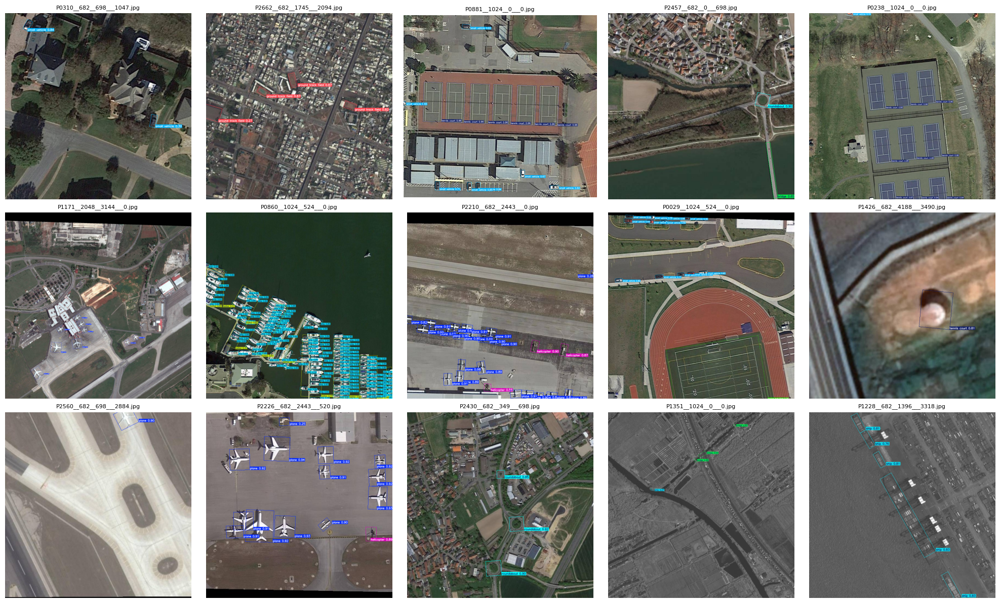

In [ ]:
sample_images = random.sample(images, 15)

fig, axes = plt.subplots(
    3, 5,
    figsize=(20, 12)
)

for ax, image_path in zip(
    axes.flat,
    sample_images
):

    results = obb_model.predict(
        source=str(image_path),
        imgsz=1024,
        conf=0.25,
        device=device,
        verbose=False
    )

    result = results[0]

    annotated = result.plot(
        font_size=7,
        line_width=1
    )

    ax.imshow(
        cv2.cvtColor(
            annotated,
            cv2.COLOR_BGR2RGB
        )
    )

    ax.set_title(
        image_path.name,
        fontsize=8
    )

    ax.axis("off")

plt.tight_layout()
plt.show()